In [1]:
# =============================================
# IMPORT
# =============================================
from utility.logger         import aiLogger
from keras.callbacks        import EarlyStopping, ReduceLROnPlateau
from model.componentModel   import mainModel
from preProcessingDataTEP   import PreProcessData
from keras.optimizers       import Adam
from utility.matpilotDraw   import MatPlot
from sklearn.preprocessing  import MinMaxScaler

import tensorflow           as tf
import pandas               as pd
import matplotlib.pyplot    as plt
import numpy                as np
import os, warnings
import random
import json


2025-01-31 17:35:35.903736: I tensorflow/core/platform/cpu_feature_guard.cc:193] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  AVX2 FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.
2025-01-31 17:35:36.207498: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcudart.so.11.0'; dlerror: libcudart.so.11.0: cannot open shared object file: No such file or directory
2025-01-31 17:35:36.207514: I tensorflow/stream_executor/cuda/cudart_stub.cc:29] Ignore above cudart dlerror if you do not have a GPU set up on your machine.
2025-01-31 17:35:36.247451: E tensorflow/stream_executor/cuda/cuda_blas.cc:2981] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2025-01-31 17:35:37.292100: W tensorflow/stream_executor/platform/de

In [2]:
# ---------------------------
# Loading config file
# ---------------------------
with open('utility/modelConfig.json', 'r') as configFile:
    configData = json.load(configFile)
config = configData["tep"]  

# ---------------------------
# Set debug level and 
# ---------------------------
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '1'  # or any {'0', '1', '2'}
warnings.filterwarnings('ignore') 

os.environ["CUDA_VISIBLE_DEVICES"] = "0" 
np.random.seed(1)
random.seed(1)
tf.random.set_seed(1)

outputDir              = os.path.expanduser(config["dataDir"])

#### Preprocessing data

In [3]:
# ==============================
# Config and data preprocessing
# ==============================
preData             = PreProcessData(config=config)
rawData             = preData.loadDataFromH5Format(dir = outputDir,case="all")
withRULData         = preData.addRULAndEnvironment(rawData)
withoutInitRawData  = preData.removeInitState(inData= withRULData)

# ---------------------------
# For data
cleanData           = preData.cleanData(rawSignal           =   withoutInitRawData,
                                        columnName          =   preData.allWithoutLabel,
                                        getMovingAverage    =   False,
                                        flipToDown          =   False)
# ---------------------------
# For label, flip only
cleanData           = preData.cleanData(rawSignal           =   cleanData,
                                        columnName          =   preData.degraLiq,
                                        getMovingAverage    =   False,
                                        flipToDown          =   False)
norData             = preData.normalizeDataEachModes(rawData    = cleanData,
                                                     headline   =   preData.headline["allWithoutLabelNoBias"] + ["rul"])                  # Normalize the data

# ---------------------------
# Extract the data in each Case
# data                = norData[config["case"]]
data                = norData[2]
trajectID           = data["Id"]
reactor             = data[preData.headline["reactor"]]
separator           = data[preData.headline["separator"]]
stripper            = data[preData.headline["stripper"]]
allSensor           = data[preData.headline["allWithoutLabelNoBias"]]
rul                 = data["rul"]
env                 = data["environmentID"]
timeTraj            = data["Time"]


# allSeqRul = []
# for idx in range(100):
#     getAtIdx = idx + 1
#     print(f"Getting the HI at the idx {getAtIdx}")
#     seqRul, seqXAllSensorTrain     = preData.getTensorData( dataList    = [rul,allSensor],
#                                                             trajectId    = trajectID,
#                                                             getAtIdx    = getAtIdx,   
#                                                                     )
#     allSeqRul.append(seqRul)


Process:45833||2025-01-31 17:35:39,442-INFO [preProcessingDataTEP.py:loadDataFromH5Format():267]:Loading data from H5 files ...
Process:45833||2025-01-31 17:35:40,802-INFO [preProcessingDataTEP.py:loadDataFromH5Format():281]:Finish loading data from H5 files at case all...
Process:45833||2025-01-31 17:35:41,031-INFO [preProcessingDataTEP.py:addRULAndEnvironment():329]:Adding rul successfully...
Process:45833||2025-01-31 17:35:42,512-INFO [preProcessingDataTEP.py:cleanData():405]:Cleaning data ...
Process:45833||2025-01-31 17:35:42,513-INFO [preProcessingDataTEP.py:cleanData():405]:Cleaning data ...
Process:45833||2025-01-31 17:35:42,513-INFO [preProcessingDataTEP.py:normalizeDataEachModes():645]:Normalizing the data ...


#### Declare the model

In [4]:
vae = mainModel(config = config)
vae.build(input_shape=(None, config["seqLength"], config["in" + config["component"]]))
vae.summary()
vae.load_weights(outputDir + "checkpoint/bestModel/")

2025-01-31 17:35:46.721914: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:980] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2025-01-31 17:35:46.722216: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcudart.so.11.0'; dlerror: libcudart.so.11.0: cannot open shared object file: No such file or directory
2025-01-31 17:35:46.722331: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcublas.so.11'; dlerror: libcublas.so.11: cannot open shared object file: No such file or directory
2025-01-31 17:35:46.722399: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcublasLt.so.11'; dlerror: libcublasLt.so.11: cannot open shared object file: No such file or directory
2025-01-31 17:35:46.722462: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Co

The shape of sysHILayer (None, 8, 5)
The shape of sysHILayer (None, 8, 5)
Model: "main_model"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 sensor_selection (SensorSel  multiple                 45        
 ection)                                                         
                                                                 
 encoder (Functional)        [(None, 1),               103906    
                              (None, 8, 5)]                      
                                                                 
 decoder (Functional)        (None, 128, 45)           103945    
                                                                 
 hi_system_and_rul (HiSystem  multiple                 6413      
 AndRul)                                                         
                                                                 
Total params: 214,320
Trainable params: 214,309


Process:45833||2025-01-31 17:35:48,153-INFO [componentModel.py:load_weights():807]:Loading the model at the direction: /home/ducan/Desktop/Dropbox/codeData/tepDataWithoutGit/checkpoint/bestModel/
Process:45833||2025-01-31 17:35:48,183-INFO [componentModel.py:load_weights():817]:Loaded the model at the direction:/home/ducan/Desktop/Dropbox/codeData/tepDataWithoutGit/checkpoint/bestModel/ successfully!!!


#### Extract information

In [6]:
result              = {"hi": [], "rul":[]}
timeEachCase        = withoutInitRawData[2].groupby('Id',sort=False)['Time']
trajecTime          = [eachTrajectTime[1] for eachTrajectTime in timeEachCase]                  #Extract time from the tuple and groupby
# for eachTrajectTime in timeEachCase:
#     print(len(eachTrajectTime)) 

for idx in range(100):
    getAtIdx = idx + 1
    print(f"Getting the HI at the idx {getAtIdx}")
    seqXTrainEnv, seqXAllSensorTrain,seqTime     = preData.getTensorData(   dataList    = [env,allSensor,timeTraj],
                                                                            trajectId   = trajectID,
                                                                            getAtIdx    = getAtIdx,   
                                                                            seqLength   = config["seqLength"],
                                                                            overlap     = config["overLap"]
                                                                        )
    seqTimeTrain        = seqTime[:,-1,:]


    hi, binaryMask,probs, rul            = vae.getHIandRUL(seqXAllSensorTrain)
    # squeezedHiSystem                    = tf.reduce_mean(hiSystem,axis=-1)
    # print(squeezedHiSystem.shape)
    squeezedRul                         = tf.squeeze(rul, axis=-1)
    
    result["hi"].append(hi)
    # result["separator"].append(hiSep)
    # result["stripper"].append(hiStrip)
    # result["system"].append(squeezedHiSystem)
    result["rul"].append(squeezedRul)




Process:45833||2025-01-31 17:36:07,317-INFO [preProcessingDataTEP.py:getTensorData():706]:Spliting data into sequences now ...


Getting the HI at the idx 1


Process:45833||2025-01-31 17:36:07,975-INFO [preProcessingDataTEP.py:getTensorData():706]:Spliting data into sequences now ...


Getting the HI at the idx 2


Process:45833||2025-01-31 17:36:08,419-INFO [preProcessingDataTEP.py:getTensorData():706]:Spliting data into sequences now ...


Getting the HI at the idx 3


... (190 outputs left out)

Process:45833||2025-01-31 17:36:52,343-INFO [preProcessingDataTEP.py:getTensorData():706]:Spliting data into sequences now ...


Getting the HI at the idx 99


Process:45833||2025-01-31 17:36:52,766-INFO [preProcessingDataTEP.py:getTensorData():706]:Spliting data into sequences now ...


Getting the HI at the idx 100


In [6]:
print(result["hi"])
# print(len(result["system"]))
# print(squeezedHiSystem.shape)
# print(hiReac.shape)
# combinedSystem  = np.vstack(result["system"])


# scaler3 = MinMaxScaler()
# scaler3.fit(combinedSystem)  # fit on combined data
# scaledHiSystem = [scaler3.transform(hi) for hi in result["system"]]

[<tf.Tensor: shape=(2012, 1), dtype=float32, numpy=
array([[   6.3291674],
       [   6.2956357],
       [   6.431317 ],
       ...,
       [3308.3682   ],
       [3314.237    ],
       [3347.583    ]], dtype=float32)>, <tf.Tensor: shape=(2174, 1), dtype=float32, numpy=
array([[   6.3329263],
       [   6.296123 ],
       [   6.4336786],
       ...,
       [5602.446    ],
       [5555.0015   ],
       [5653.654    ]], dtype=float32)>, <tf.Tensor: shape=(2182, 1), dtype=float32, numpy=
array([[   6.333926 ],
       [   6.2970867],
       [   6.4334826],
       ...,
       [5728.9097   ],
       [5730.8584   ],
       [5783.892    ]], dtype=float32)>, <tf.Tensor: shape=(2190, 1), dtype=float32, numpy=
array([[   6.3295646],
       [   6.2710805],
       [   6.435097 ],
       ...,
       [5916.9253   ],
       [5897.817    ],
       [5912.22     ]], dtype=float32)>, <tf.Tensor: shape=(2027, 1), dtype=float32, numpy=
array([[   6.324672 ],
       [   6.266814 ],
       [   6.4200974],
   

In [7]:
print(result["rul"][0].shape)

(2012,)


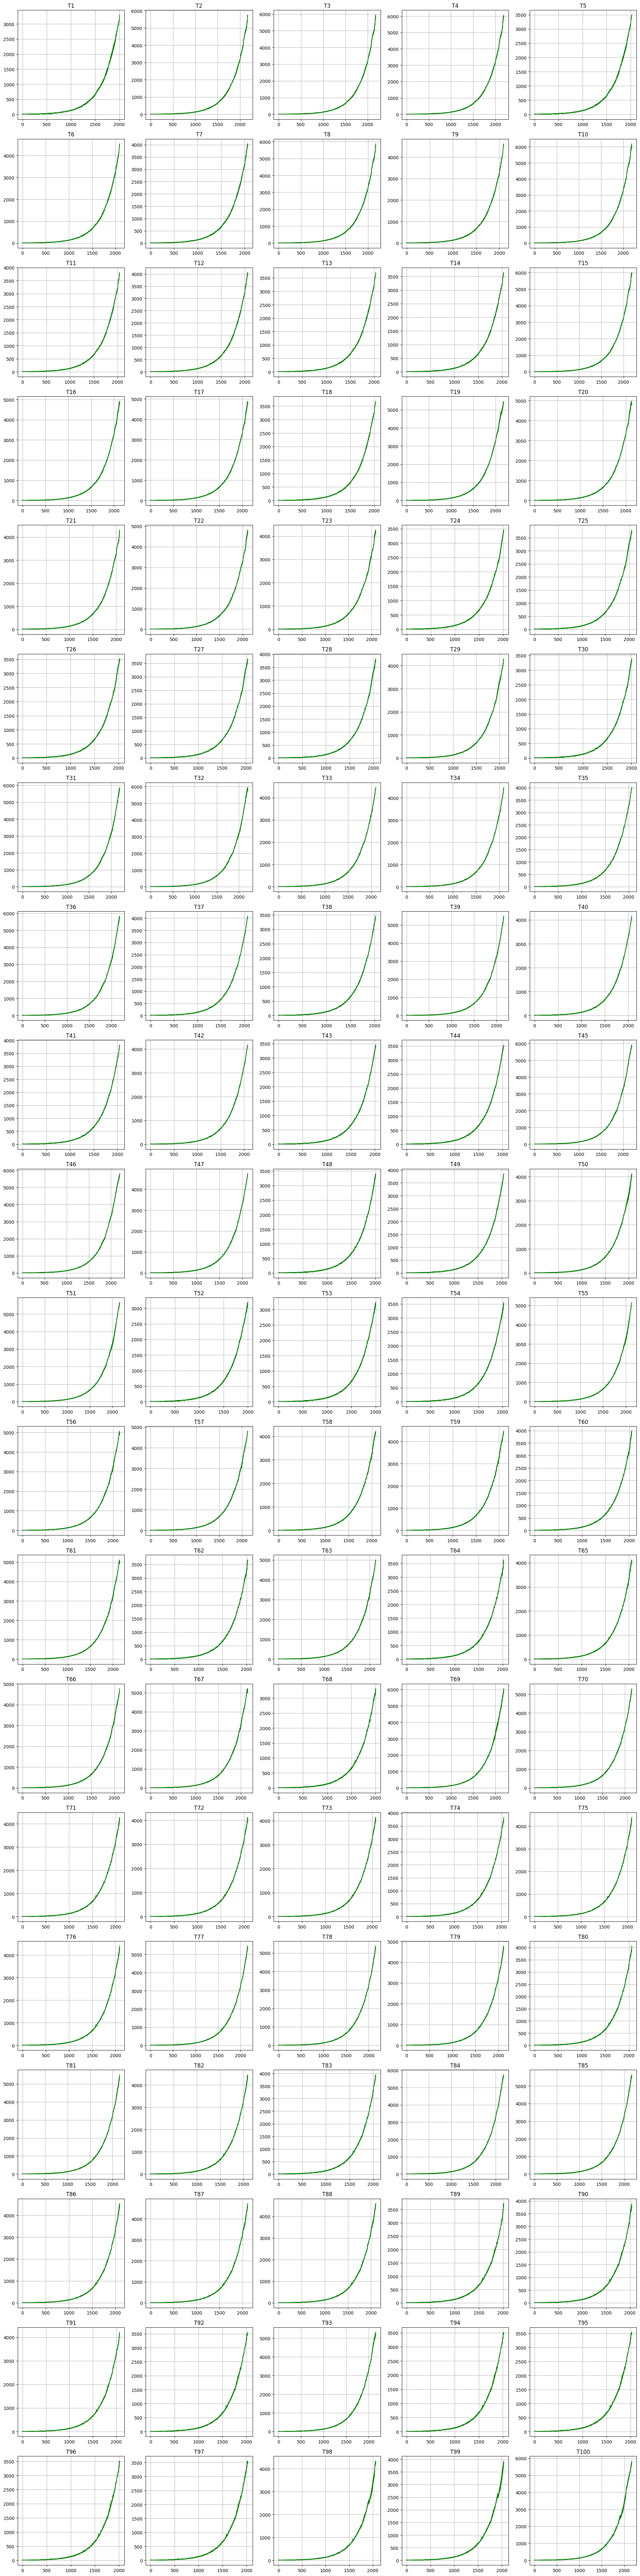

In [7]:
plot1 = MatPlot() 
plot1.subPlotMultiImg(inY = [result["hi"]], color=['g'], numRow=20, numCol=5)

In [9]:
plot1 = MatPlot()
plot1.subPlotMultiImg(inY = [result["reactor"],result["separator"],result["stripper"]], color=['g','y','b'], numRow=20, numCol=5)

plot3 = MatPlot()
plot3.subPlotMultiImg(inY = [result["system"]], color=['r'], numRow=20, numCol=5)

# plot1.subPlotMultiImg(inY = [scaledHiReac,scaledHiSep,scaledHiStrip, scaledHiSystem], color=['g','y','b','r'], numRow=20, numCol=5)

plot2 = MatPlot()
plot2.subPlotMultiImg(inY = [result["rul"]],  numRow=20, numCol=5)



KeyError: 'reactor'